# M7 — Train–Test Comparative Exploratory Data Analysis

## M7.1 — Binary Class Distribution Comparison

### Objective

Compare the proportion of Normal and Attack records
between training and testing partitions of NSL-KDD
and UNSW-NB15.

This analysis investigates differences in class
composition between the two partitions.

All original records are preserved.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

current_dir = Path.cwd()

project_dir = (
    current_dir.parent
    if current_dir.name == "notebooks"
    else current_dir
)

nsl_columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "attack_type", "difficulty_level"
]

nsl_train = pd.read_csv(
    project_dir / "data/raw/nsl_kdd/KDDTrain+.txt",
    names=nsl_columns,
    header=None
)

nsl_test = pd.read_csv(
    project_dir / "data/raw/nsl_kdd/KDDTest+.txt",
    names=nsl_columns,
    header=None
)

unsw_train = pd.read_csv(
    project_dir / "data/raw/unsw_nb15/UNSW_NB15_training-set.csv"
)

unsw_test = pd.read_csv(
    project_dir / "data/raw/unsw_nb15/UNSW_NB15_testing-set.csv"
)

print("NSL-KDD Train:", nsl_train.shape)
print("NSL-KDD Test:", nsl_test.shape)

print("UNSW-NB15 Train:", unsw_train.shape)
print("UNSW-NB15 Test:", unsw_test.shape)

NSL-KDD Train: (125973, 43)
NSL-KDD Test: (22544, 43)
UNSW-NB15 Train: (175341, 45)
UNSW-NB15 Test: (82332, 45)


In [2]:
datasets = {
    ("NSL-KDD", "Train"): nsl_train.copy(deep=True),
    ("NSL-KDD", "Test"): nsl_test.copy(deep=True),
    ("UNSW-NB15", "Train"): unsw_train.copy(deep=True),
    ("UNSW-NB15", "Test"): unsw_test.copy(deep=True)
}

for (dataset_name, partition), df in datasets.items():

    if dataset_name == "NSL-KDD":

        df["traffic_class"] = np.where(
            df["attack_type"] == "normal",
            "Normal",
            "Attack"
        )

    else:

        df["traffic_class"] = np.where(
            df["label"] == 0,
            "Normal",
            "Attack"
        )

print("SUCCESS: Binary traffic labels created!")

SUCCESS: Binary traffic labels created!


In [3]:
class_comparison_results = []

for (dataset_name, partition), df in datasets.items():

    total = len(df)

    for traffic_class in ["Normal", "Attack"]:

        count = (
            df["traffic_class"] == traffic_class
        ).sum()

        percentage = count / total * 100

        class_comparison_results.append({
            "Dataset": dataset_name,
            "Partition": partition,
            "Traffic Class": traffic_class,
            "Count": count,
            "Percentage": round(percentage, 2)
        })

class_comparison_df = pd.DataFrame(
    class_comparison_results
)

display(class_comparison_df)

,Dataset,Partition,Traffic Class,Count,Percentage
0,NSL-KDD,Train,Normal,67343,53.46
1,NSL-KDD,Train,Attack,58630,46.54
2,NSL-KDD,Test,Normal,9711,43.08
3,NSL-KDD,Test,Attack,12833,56.92
4,UNSW-NB15,Train,Normal,56000,31.94
5,UNSW-NB15,Train,Attack,119341,68.06
6,UNSW-NB15,Test,Normal,37000,44.94
7,UNSW-NB15,Test,Attack,45332,55.06


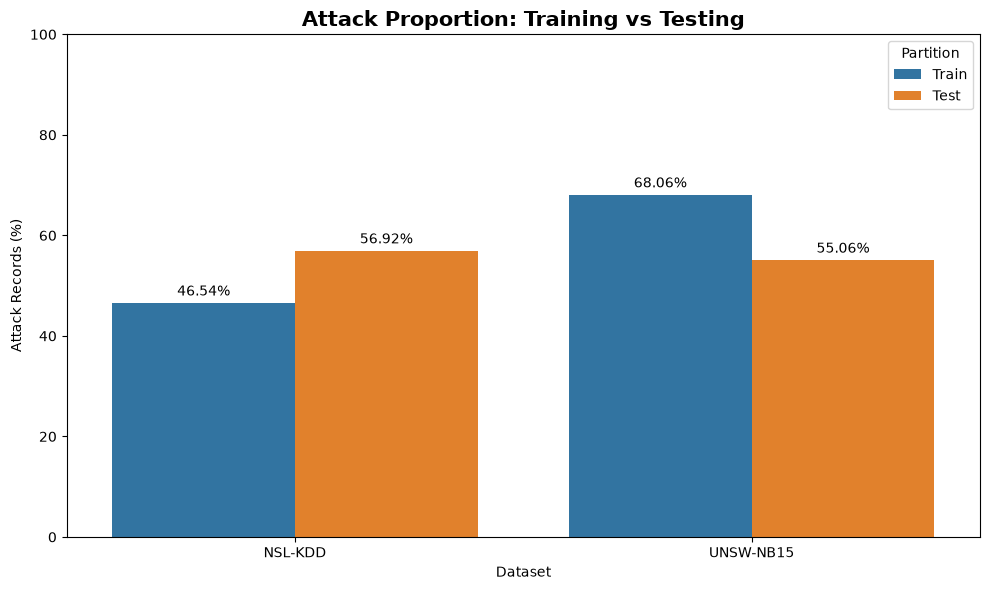

Chart saved: True


In [4]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=class_comparison_df,
    x="Dataset",
    y="Percentage",
    hue="Partition",
    order=["NSL-KDD", "UNSW-NB15"],
    hue_order=["Train", "Test"],
    errorbar=None
)

plt.title(
    "Train vs Test: Class Distribution Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Percentage (%)")
plt.xlabel("Dataset")

plt.ylim(0, 100)

# Show class-specific values in a clearer separate chart
plt.close()

attack_comparison_df = class_comparison_df[
    class_comparison_df["Traffic Class"] == "Attack"
]

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=attack_comparison_df,
    x="Dataset",
    y="Percentage",
    hue="Partition",
    hue_order=["Train", "Test"],
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.title(
    "Attack Proportion: Training vs Testing",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Attack Records (%)")
plt.xlabel("Dataset")
plt.ylim(0, 100)

plt.tight_layout()

output_path = (
    project_dir
    / "figures/comparative"
    / "train_test_attack_proportions.png"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", output_path.exists())

In [5]:
assert len(class_comparison_df) == 8

assert output_path.exists()

for (dataset_name, partition), df in datasets.items():

    subset = class_comparison_df[
        (class_comparison_df["Dataset"] == dataset_name)
        & (class_comparison_df["Partition"] == partition)
    ]

    assert subset["Count"].sum() == len(df)

    assert abs(subset["Percentage"].sum() - 100) < 0.02

print("SUCCESS: M7.1 train-test class comparison validated!")

SUCCESS: M7.1 train-test class comparison validated!


## M7.2 — Attack Category Comparison and Unseen Attack Types

### Objective

Compare attack-type distributions between training and testing
partitions of NSL-KDD and UNSW-NB15.

Identify attack labels that appear exclusively in either partition.

The analysis uses original attack labels and excludes Normal
traffic when calculating attack-category percentages.

In [6]:
nsl_train_attacks = set(
    nsl_train.loc[
        nsl_train["attack_type"] != "normal",
        "attack_type"
    ].unique()
)

nsl_test_attacks = set(
    nsl_test.loc[
        nsl_test["attack_type"] != "normal",
        "attack_type"
    ].unique()
)

nsl_shared = nsl_train_attacks & nsl_test_attacks

nsl_test_only = nsl_test_attacks - nsl_train_attacks

nsl_train_only = nsl_train_attacks - nsl_test_attacks

print("NSL-KDD Attack Type Comparison")
print("-" * 40)

print("Training attack types:", len(nsl_train_attacks))
print("Testing attack types:", len(nsl_test_attacks))
print("Shared attack types:", len(nsl_shared))

print("\nTest-only attack types:")
print(sorted(nsl_test_only))

print("\nTrain-only attack types:")
print(sorted(nsl_train_only))

NSL-KDD Attack Type Comparison
----------------------------------------
Training attack types: 22
Testing attack types: 37
Shared attack types: 20

Test-only attack types:
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']

Train-only attack types:
['spy', 'warezclient']


In [7]:
unsw_train_attacks = set(
    unsw_train.loc[
        unsw_train["label"] == 1,
        "attack_cat"
    ].unique()
)

unsw_test_attacks = set(
    unsw_test.loc[
        unsw_test["label"] == 1,
        "attack_cat"
    ].unique()
)

unsw_shared = unsw_train_attacks & unsw_test_attacks

unsw_test_only = unsw_test_attacks - unsw_train_attacks

unsw_train_only = unsw_train_attacks - unsw_test_attacks

print("UNSW-NB15 Attack Category Comparison")
print("-" * 40)

print("Training attack categories:", len(unsw_train_attacks))
print("Testing attack categories:", len(unsw_test_attacks))
print("Shared categories:", len(unsw_shared))

print("\nTest-only categories:")
print(sorted(unsw_test_only))

print("\nTrain-only categories:")
print(sorted(unsw_train_only))

UNSW-NB15 Attack Category Comparison
----------------------------------------
Training attack categories: 9
Testing attack categories: 9
Shared categories: 9

Test-only categories:
[]

Train-only categories:
[]


In [8]:
def compare_attack_categories(
    train_df,
    test_df,
    category_column,
    train_attack_mask,
    test_attack_mask
):

    train_counts = (
        train_df.loc[train_attack_mask, category_column]
        .value_counts()
    )

    test_counts = (
        test_df.loc[test_attack_mask, category_column]
        .value_counts()
    )

    comparison = pd.DataFrame({
        "Train Count": train_counts,
        "Test Count": test_counts
    }).fillna(0)

    comparison = comparison.astype(int)

    train_total = train_counts.sum()
    test_total = test_counts.sum()

    comparison["Train %"] = (
        comparison["Train Count"] / train_total * 100
    ).round(2)

    comparison["Test %"] = (
        comparison["Test Count"] / test_total * 100
    ).round(2)

    comparison["Percentage Point Change"] = (
        comparison["Test %"] - comparison["Train %"]
    ).round(2)

    comparison = comparison.sort_values(
        "Train Count",
        ascending=False
    )

    return comparison

In [9]:
nsl_attack_comparison = compare_attack_categories(
    nsl_train,
    nsl_test,
    "attack_type",
    nsl_train["attack_type"] != "normal",
    nsl_test["attack_type"] != "normal"
)

print("NSL-KDD Attack Type Comparison")

display(nsl_attack_comparison.head(15))

NSL-KDD Attack Type Comparison


,Train Count,Test Count,Train %,Test %,Percentage Point Change
attack_type,,,,,
neptune,41214,4657,70.30,36.29,-34.01
satan,3633,735,6.20,5.73,-0.47
ipsweep,3599,141,6.14,1.10,-5.04
portsweep,2931,157,5.00,1.22,-3.78
smurf,2646,665,4.51,5.18,0.67
nmap,1493,73,2.55,0.57,-1.98
back,956,359,1.63,2.80,1.17
teardrop,892,12,1.52,0.09,-1.43
warezclient,890,0,1.52,0.00,-1.52


In [10]:
unsw_attack_comparison = compare_attack_categories(
    unsw_train,
    unsw_test,
    "attack_cat",
    unsw_train["label"] == 1,
    unsw_test["label"] == 1
)

print("UNSW-NB15 Attack Category Comparison")

display(unsw_attack_comparison)

UNSW-NB15 Attack Category Comparison


,Train Count,Test Count,Train %,Test %,Percentage Point Change
attack_cat,,,,,
Generic,40000,18871,33.52,41.63,8.11
Exploits,33393,11132,27.98,24.56,-3.42
Fuzzers,18184,6062,15.24,13.37,-1.87
DoS,12264,4089,10.28,9.02,-1.26
Reconnaissance,10491,3496,8.79,7.71,-1.08
Analysis,2000,677,1.68,1.49,-0.19
Backdoor,1746,583,1.46,1.29,-0.17
Shellcode,1133,378,0.95,0.83,-0.12
Worms,130,44,0.11,0.10,-0.01


In [11]:
def plot_attack_comparison(
    comparison_df,
    dataset_name,
    filename,
    top_n=10
):

    plot_df = comparison_df.head(top_n)[
        ["Train %", "Test %"]
    ].copy()

    plot_df = plot_df.reset_index()

    category_column = plot_df.columns[0]

    plot_df = plot_df.melt(
        id_vars=category_column,
        value_vars=["Train %", "Test %"],
        var_name="Partition",
        value_name="Percentage"
    )

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=plot_df,
        x="Percentage",
        y=category_column,
        hue="Partition",
        errorbar=None
    )

    plt.title(
        f"{dataset_name}: Train vs Test Attack Distribution",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Percentage of Attack Records (%)")
    plt.ylabel("Attack Category")

    plt.tight_layout()

    output_path = (
        project_dir
        / "figures"
        / "comparative"
        / filename
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path.exists())

    return output_path

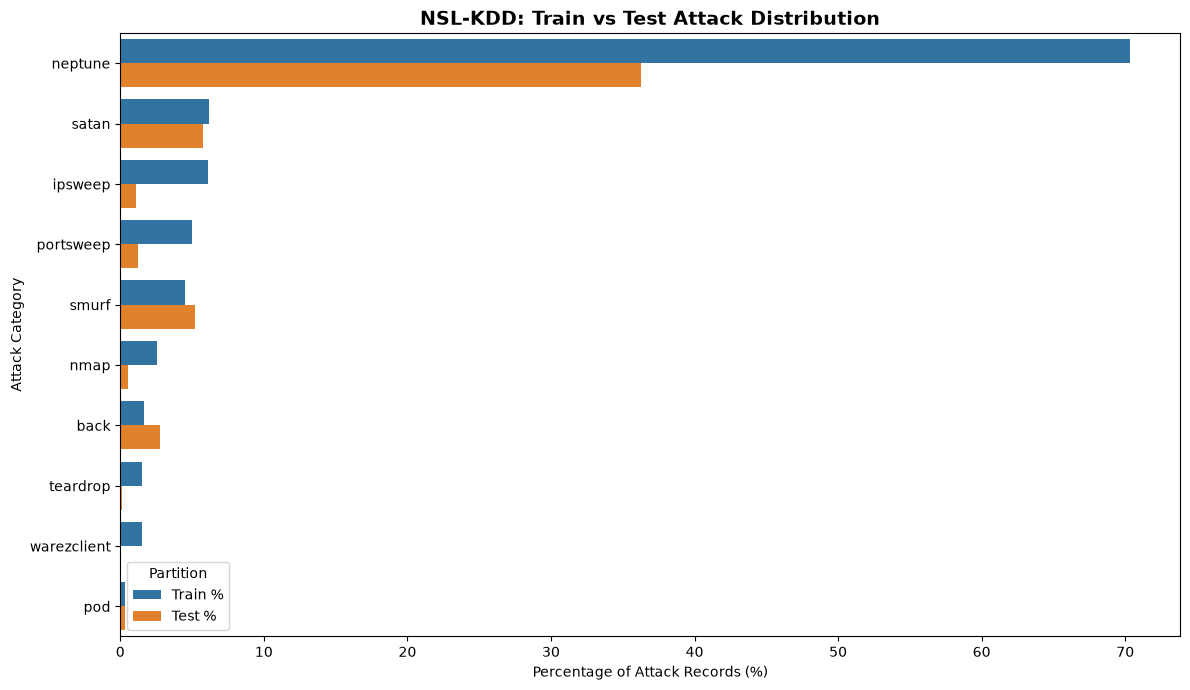

Saved: True


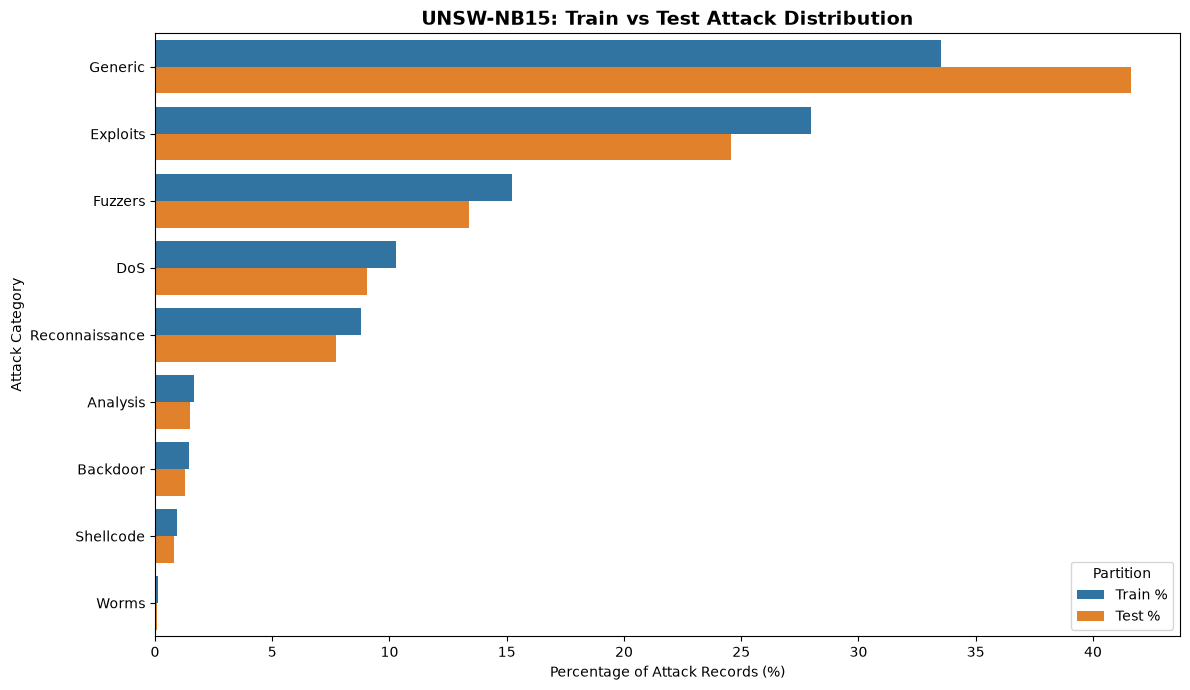

Saved: True


In [12]:
nsl_attack_chart_path = plot_attack_comparison(
    nsl_attack_comparison,
    "NSL-KDD",
    "nsl_attack_train_test_comparison.png"
)

unsw_attack_chart_path = plot_attack_comparison(
    unsw_attack_comparison,
    "UNSW-NB15",
    "unsw_attack_train_test_comparison.png"
)

In [13]:
assert nsl_attack_comparison["Train Count"].sum() == 58630
assert nsl_attack_comparison["Test Count"].sum() == 12833

assert unsw_attack_comparison["Train Count"].sum() == 119341
assert unsw_attack_comparison["Test Count"].sum() == 45332

assert nsl_attack_chart_path.exists()
assert unsw_attack_chart_path.exists()

assert nsl_train_attacks == (
    nsl_shared | nsl_train_only
)

assert nsl_test_attacks == (
    nsl_shared | nsl_test_only
)

assert unsw_train_attacks == (
    unsw_shared | unsw_train_only
)

assert unsw_test_attacks == (
    unsw_shared | unsw_test_only
)

print("SUCCESS: M7.2 attack category comparison validated!")

SUCCESS: M7.2 attack category comparison validated!


## M7.3 — Numerical Feature Distribution Shift

### Objective

Compare selected numerical feature distributions between
training and testing partitions.

Methods:
- Median comparison
- 90th-percentile comparison
- Kolmogorov–Smirnov statistic
- Log-transformed distribution visualizations

The analysis is performed separately for NSL-KDD
and UNSW-NB15.

In [14]:
from scipy.stats import ks_2samp

print("SUCCESS: KS test imported!")

SUCCESS: KS test imported!


In [15]:
numerical_comparison_config = {
    "NSL-KDD": {
        "train": nsl_train,
        "test": nsl_test,
        "features": [
            "duration",
            "src_bytes",
            "dst_bytes"
        ]
    },

    "UNSW-NB15": {
        "train": unsw_train,
        "test": unsw_test,
        "features": [
            "dur",
            "sbytes",
            "dbytes"
        ]
    }
}

for dataset_name, config in numerical_comparison_config.items():

    print(f"\n{dataset_name}")

    for feature in config["features"]:

        assert feature in config["train"].columns
        assert feature in config["test"].columns

        print("Verified:", feature)


NSL-KDD
Verified: duration
Verified: src_bytes
Verified: dst_bytes

UNSW-NB15
Verified: dur
Verified: sbytes
Verified: dbytes


In [16]:
numerical_shift_results = []

for dataset_name, config in numerical_comparison_config.items():

    train_df = config["train"]
    test_df = config["test"]

    for feature in config["features"]:

        train_values = train_df[feature].dropna()
        test_values = test_df[feature].dropna()

        ks_result = ks_2samp(
            train_values,
            test_values,
            alternative="two-sided",
            method="auto"
        )

        numerical_shift_results.append({
            "Dataset": dataset_name,
            "Feature": feature,
            "Train Median": train_values.median(),
            "Test Median": test_values.median(),
            "Train P90": train_values.quantile(0.90),
            "Test P90": test_values.quantile(0.90),
            "KS Statistic": ks_result.statistic,
            "KS P-value": ks_result.pvalue
        })

numerical_shift_df = pd.DataFrame(
    numerical_shift_results
)

display(numerical_shift_df.round(4))

,Dataset,Feature,Train Median,Test Median,Train P90,Test P90,KS Statistic,KS P-value
0,NSL-KDD,duration,0.0000,0.0000,0.0000,4.000,0.0769,0.0
1,NSL-KDD,src_bytes,44.0000,54.0000,848.0000,1032.000,0.0817,0.0
2,NSL-KDD,dst_bytes,0.0000,46.0000,3375.8000,4099.100,0.1241,0.0
3,UNSW-NB15,dur,0.0016,0.0141,1.5101,1.404,0.0890,0.0
4,UNSW-NB15,sbytes,430.0000,534.0000,4190.0000,3851.600,0.0466,0.0
5,UNSW-NB15,dbytes,164.0000,178.0000,10168.0000,10168.000,0.0437,0.0


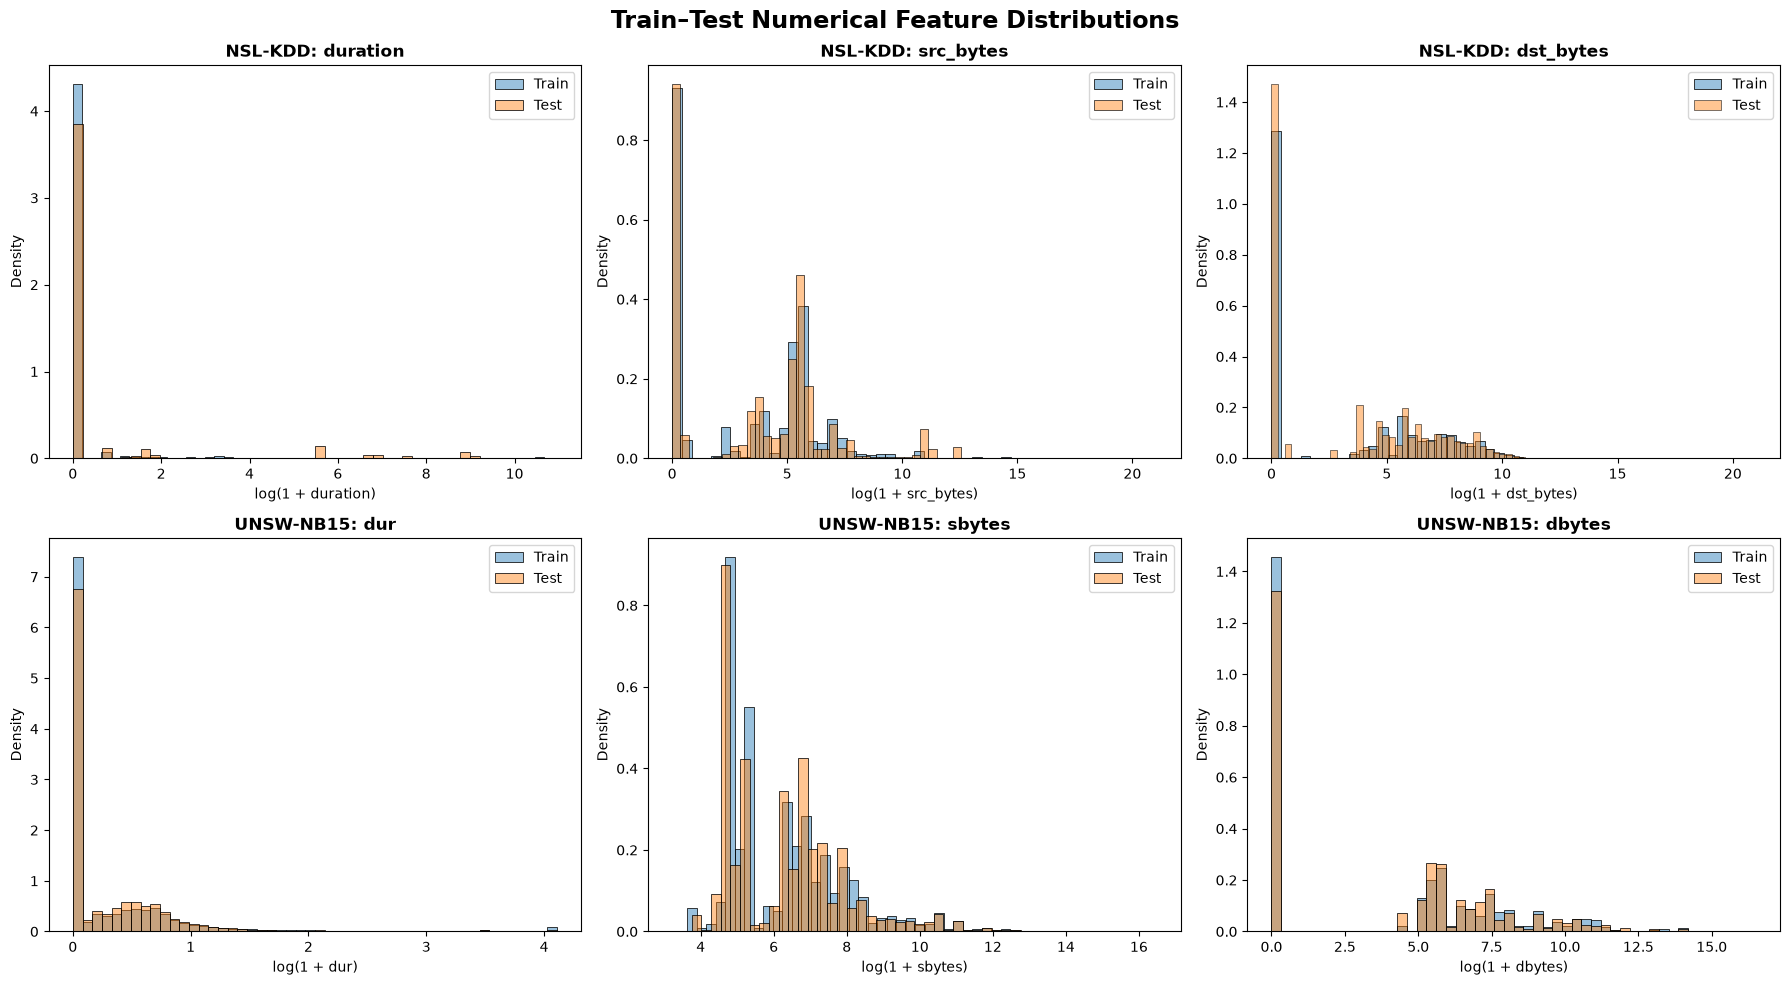

Chart saved: True


In [17]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

for row_index, (dataset_name, config) in enumerate(
    numerical_comparison_config.items()
):

    for col_index, feature in enumerate(config["features"]):

        ax = axes[row_index, col_index]

        train_values = np.log1p(
            config["train"][feature].dropna()
        )

        test_values = np.log1p(
            config["test"][feature].dropna()
        )

        sns.histplot(
            train_values,
            bins=50,
            stat="density",
            alpha=0.45,
            label="Train",
            ax=ax
        )

        sns.histplot(
            test_values,
            bins=50,
            stat="density",
            alpha=0.45,
            label="Test",
            ax=ax
        )

        ax.set_title(
            f"{dataset_name}: {feature}",
            fontweight="bold"
        )

        ax.set_xlabel(f"log(1 + {feature})")
        ax.set_ylabel("Density")
        ax.legend()

plt.suptitle(
    "Train–Test Numerical Feature Distributions",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

numerical_shift_chart_path = (
    project_dir
    / "figures"
    / "comparative"
    / "train_test_numerical_distributions.png"
)

numerical_shift_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    numerical_shift_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", numerical_shift_chart_path.exists())

In [18]:
assert len(numerical_shift_df) == 6

assert numerical_shift_chart_path.exists()

assert numerical_shift_df[
    "KS Statistic"
].between(0, 1).all()

assert numerical_shift_df[
    "KS P-value"
].between(0, 1).all()

assert numerical_shift_df[
    [
        "Train Median",
        "Test Median",
        "Train P90",
        "Test P90"
    ]
].notna().all().all()

print("SUCCESS: M7.3 numerical distribution comparison validated!")

SUCCESS: M7.3 numerical distribution comparison validated!


## M7.4 — Categorical Feature Distribution Shift

### Objective

Compare categorical feature distributions between training
and testing partitions of NSL-KDD and UNSW-NB15.

Features:
- NSL-KDD: protocol_type, service, flag
- UNSW-NB15: proto, service, state

Method:
- Category proportions
- Total Variation Distance (TVD)
- Comparative visualizations

TVD measures differences between empirical category distributions.

In [19]:
categorical_shift_config = {
    "NSL-KDD": {
        "train": nsl_train,
        "test": nsl_test,
        "features": [
            "protocol_type",
            "service",
            "flag"
        ]
    },

    "UNSW-NB15": {
        "train": unsw_train,
        "test": unsw_test,
        "features": [
            "proto",
            "service",
            "state"
        ]
    }
}

for dataset_name, config in categorical_shift_config.items():

    print(f"\n{dataset_name}")

    for feature in config["features"]:

        assert feature in config["train"].columns
        assert feature in config["test"].columns

        print("Verified:", feature)


NSL-KDD
Verified: protocol_type
Verified: service
Verified: flag

UNSW-NB15
Verified: proto
Verified: service
Verified: state


In [20]:
categorical_shift_tables = {}
tvd_results = []

for dataset_name, config in categorical_shift_config.items():

    train_df = config["train"]
    test_df = config["test"]

    for feature in config["features"]:

        train_proportions = (
            train_df[feature]
            .value_counts(normalize=True)
        )

        test_proportions = (
            test_df[feature]
            .value_counts(normalize=True)
        )

        comparison = pd.DataFrame({
            "Train Proportion": train_proportions,
            "Test Proportion": test_proportions
        }).fillna(0)

        comparison["Train %"] = (
            comparison["Train Proportion"] * 100
        ).round(2)

        comparison["Test %"] = (
            comparison["Test Proportion"] * 100
        ).round(2)

        comparison["Percentage Point Change"] = (
            comparison["Test %"] - comparison["Train %"]
        ).round(2)

        tvd = 0.5 * (
            comparison["Train Proportion"]
            - comparison["Test Proportion"]
        ).abs().sum()

        comparison = comparison.sort_values(
            "Train Proportion",
            ascending=False
        )

        categorical_shift_tables[
            (dataset_name, feature)
        ] = comparison

        tvd_results.append({
            "Dataset": dataset_name,
            "Feature": feature,
            "Train Categories": train_df[feature].nunique(),
            "Test Categories": test_df[feature].nunique(),
            "TVD": tvd
        })

tvd_summary_df = pd.DataFrame(tvd_results)

display(
    tvd_summary_df.sort_values(
        "TVD",
        ascending=False
    ).round(4)
)

,Dataset,Feature,Train Categories,Test Categories,TVD
1,NSL-KDD,service,70,64,0.2049
2,NSL-KDD,flag,11,11,0.1906
3,UNSW-NB15,proto,133,131,0.0677
5,UNSW-NB15,state,9,7,0.0548
4,UNSW-NB15,service,13,13,0.0357
0,NSL-KDD,protocol_type,3,3,0.0223


In [21]:
for (dataset_name, feature), comparison in (
    categorical_shift_tables.items()
):

    print(f"\n{dataset_name} — {feature}")

    top_changes = (
        comparison
        .assign(
            Absolute_Change=lambda df: (
                df["Percentage Point Change"].abs()
            )
        )
        .sort_values(
            "Absolute_Change",
            ascending=False
        )
        .head(5)
    )

    display(
        top_changes[
            [
                "Train %",
                "Test %",
                "Percentage Point Change"
            ]
        ]
    )


NSL-KDD — protocol_type


,Train %,Test %,Percentage Point Change
protocol_type,,,
tcp,81.52,83.75,2.23
icmp,6.58,4.63,-1.95
udp,11.90,11.63,-0.27



NSL-KDD — service


,Train %,Test %,Percentage Point Change
service,,,
telnet,1.87,7.21,5.34
pop_3,0.21,4.52,4.31
private,17.35,21.18,3.83
domain_u,7.18,3.97,-3.21
http,32.02,34.83,2.81



NSL-KDD — flag


...

,Train %,Test %,Percentage Point Change
proto,,,
tcp,45.59,52.34,6.75
unas,6.89,4.27,-2.62
ospf,1.48,0.82,-0.66
arp,1.63,1.20,-0.43
udp,36.09,35.73,-0.36



UNSW-NB15 — service


,Train %,Test %,Percentage Point Change
service,,,
-,53.71,57.27,3.56
dns,26.97,25.95,-1.02
smtp,2.88,2.25,-0.63
http,10.68,10.07,-0.61
ftp-data,2.28,1.70,-0.58



UNSW-NB15 — state


,Train %,Test %,Percentage Point Change
state,,,
INT,46.92,41.49,-5.43
FIN,44.38,47.78,3.40
REQ,1.14,2.24,1.10
CON,7.50,8.48,0.98
RST,0.05,0.00,-0.05


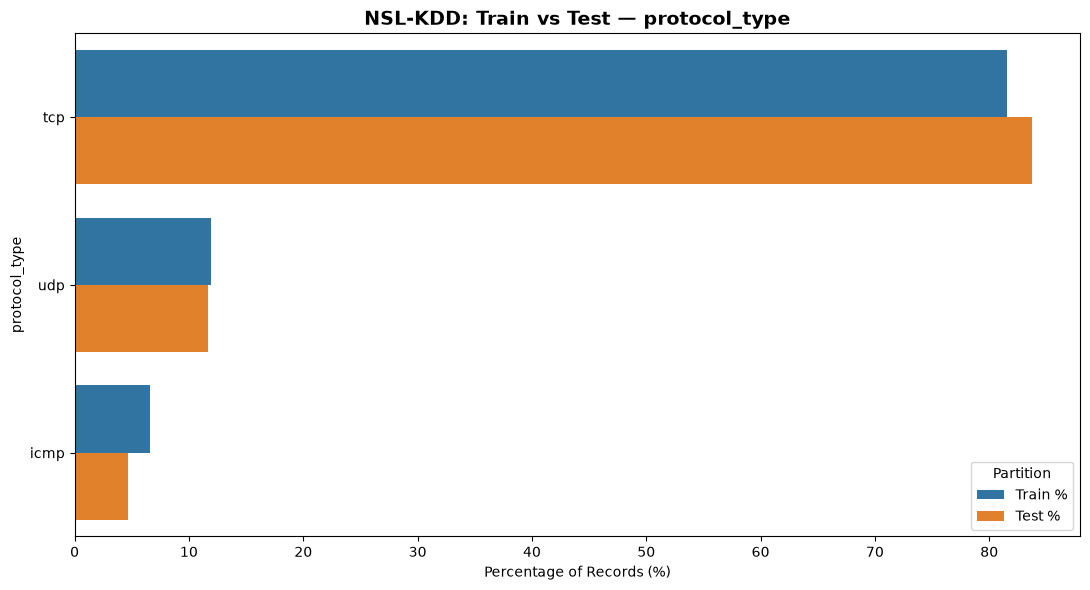

Saved: True


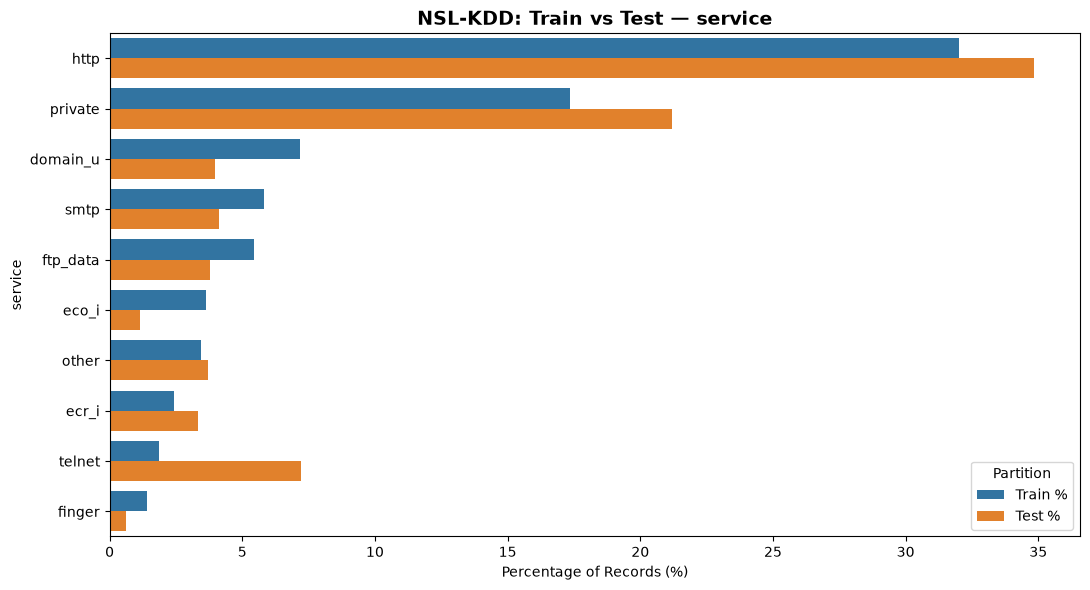

Saved: True


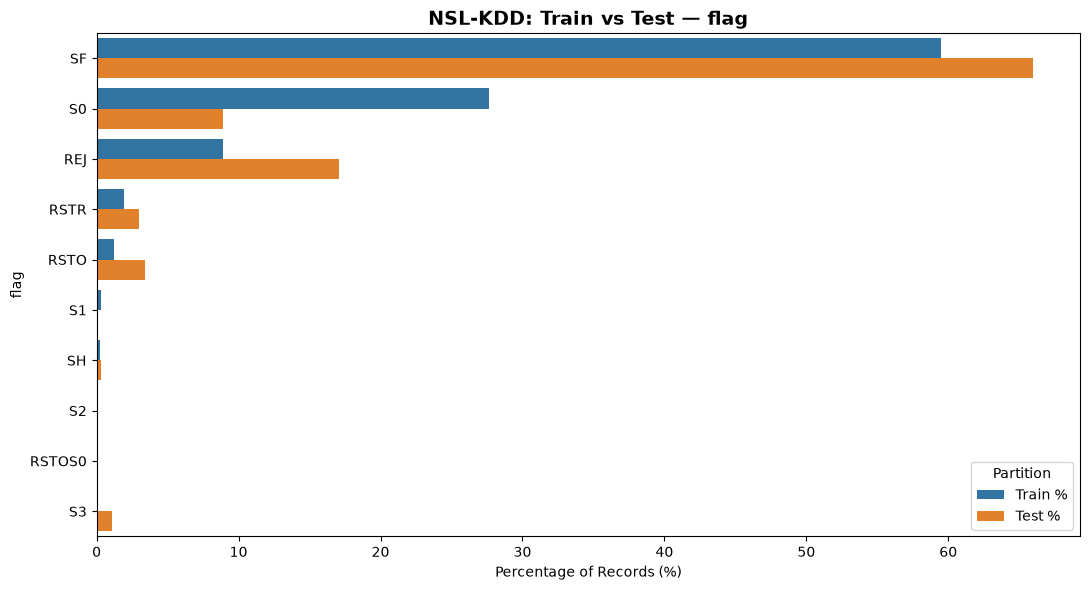

Saved: True


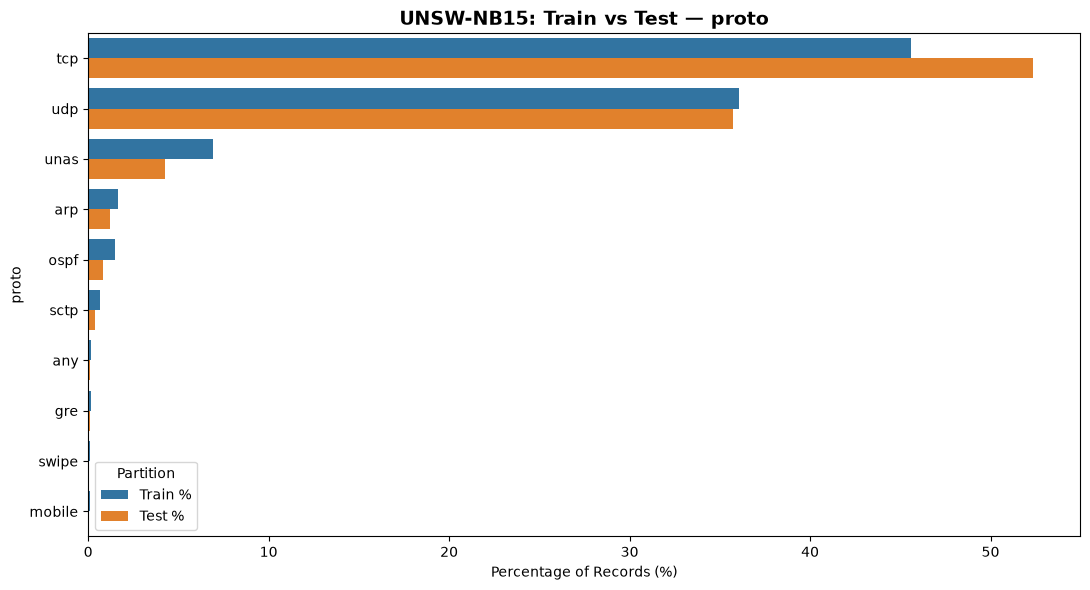

Saved: True


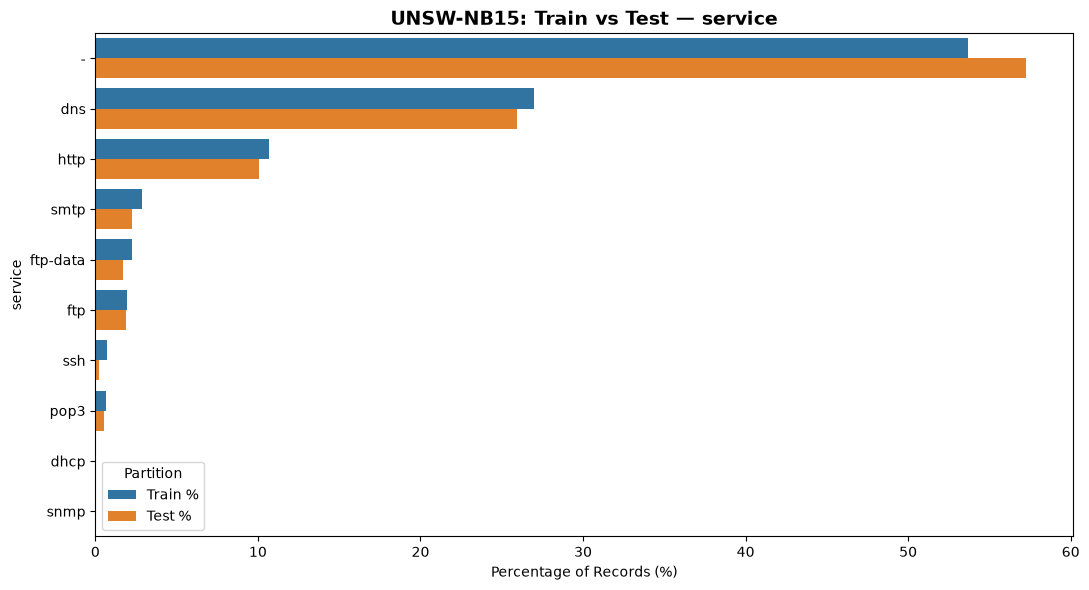

Saved: True


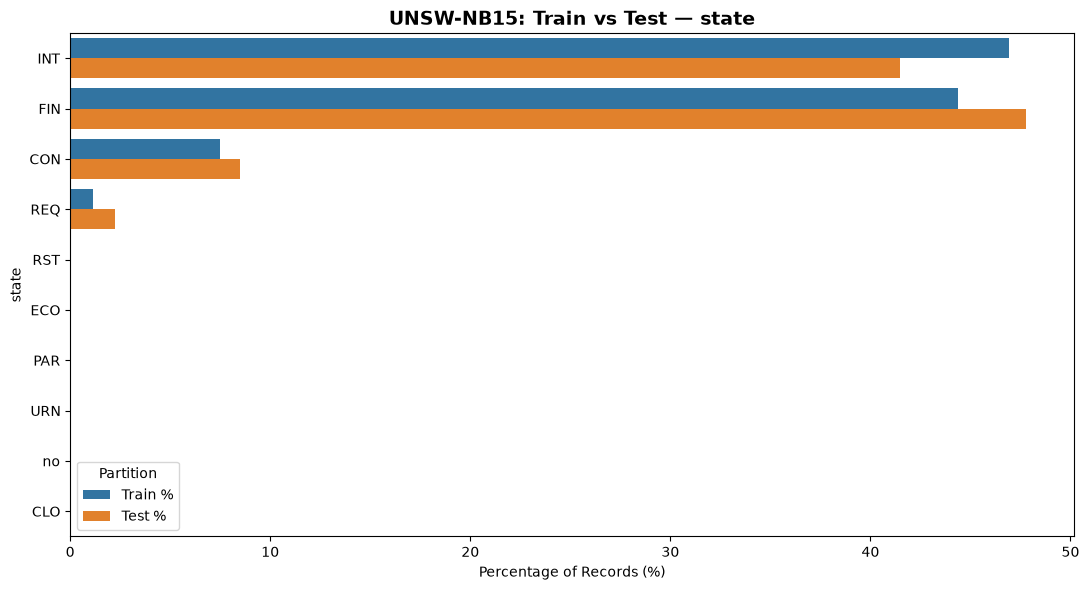

Saved: True


In [22]:
categorical_shift_chart_paths = []

for (dataset_name, feature), comparison in (
    categorical_shift_tables.items()
):

    top_categories = comparison.head(10)

    plot_df = (
        top_categories[["Train %", "Test %"]]
        .reset_index()
    )

    category_column = plot_df.columns[0]

    plot_df = plot_df.melt(
        id_vars=category_column,
        value_vars=["Train %", "Test %"],
        var_name="Partition",
        value_name="Percentage"
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=plot_df,
        x="Percentage",
        y=category_column,
        hue="Partition",
        errorbar=None
    )

    plt.title(
        f"{dataset_name}: Train vs Test — {feature}",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Percentage of Records (%)")
    plt.ylabel(feature)

    plt.tight_layout()

    filename = (
        dataset_name.lower().replace("-", "_")
        + "_"
        + feature
        + "_train_test.png"
    )

    output_path = (
        project_dir
        / "figures"
        / "comparative"
        / filename
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    categorical_shift_chart_paths.append(
        output_path
    )

    print("Saved:", output_path.exists())

In [23]:
assert len(tvd_summary_df) == 6

assert len(categorical_shift_chart_paths) == 6

assert all(
    path.exists()
    for path in categorical_shift_chart_paths
)

assert tvd_summary_df["TVD"].between(0, 1).all()

for comparison in categorical_shift_tables.values():

    assert np.isclose(
        comparison["Train Proportion"].sum(),
        1.0
    )

    assert np.isclose(
        comparison["Test Proportion"].sum(),
        1.0
    )

print("SUCCESS: M7.4 categorical distribution comparison validated!")

SUCCESS: M7.4 categorical distribution comparison validated!


In [24]:
expected_m7_figures = [
    "train_test_attack_proportions.png",
    "nsl_attack_train_test_comparison.png",
    "unsw_attack_train_test_comparison.png",
    "train_test_numerical_distributions.png",
    "nsl_kdd_protocol_type_train_test.png",
    "nsl_kdd_service_train_test.png",
    "nsl_kdd_flag_train_test.png",
    "unsw_nb15_proto_train_test.png",
    "unsw_nb15_service_train_test.png",
    "unsw_nb15_state_train_test.png"
]

figures_dir = project_dir / "figures" / "comparative"

for filename in expected_m7_figures:
    path = figures_dir / filename

    print(f"{filename}: {path.exists()}")

    assert path.exists(), f"Missing figure: {filename}"

print("\nSUCCESS: All 10 M7 visualizations verified!")

train_test_attack_proportions.png: True
nsl_attack_train_test_comparison.png: True
unsw_attack_train_test_comparison.png: True
train_test_numerical_distributions.png: True
nsl_kdd_protocol_type_train_test.png: True
nsl_kdd_service_train_test.png: True
nsl_kdd_flag_train_test.png: True
unsw_nb15_proto_train_test.png: True
unsw_nb15_service_train_test.png: True
unsw_nb15_state_train_test.png: True

SUCCESS: All 10 M7 visualizations verified!
